# Road Accident Severity Prediction

This notebook compares **Logistic Regression**, **Random Forest**, and **XGBoost** for the four recorded severity classes (1–4). It reports class imbalance, minority-class recall, macro-F1, confusion matrices, high-risk patterns, common errors, and a time-based generalization check. It also saves the selected fitted pipeline for a FastAPI service.

The results describe patterns in recorded accidents. They should help prioritize road-safety investigation, not be interpreted as proof of cause or as a way to prevent accidents directly.

The notebook scans the CSV in chunks, takes a reproducible random sample, and caps the working dataset at 100,000 rows. It uses only the columns needed for this analysis. The location holdout reserves part of that sample for evaluation; after comparing models, the selected model is retrained on the full retained sample before it is saved. This reduces memory and training time.


## 1. Install and import packages

Run the install line once if any package is missing.

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy scikit-learn xgboost matplotlib seaborn joblib

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    accuracy_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42


## 2. Read a reproducible sample of up to 100,000 rows

The notebook uses the Desktop CSV when available, or searches `/kaggle/input` for an attached Kaggle dataset. It scans the CSV in chunks, keeps a random 2% from each chunk, then caps the combined sample at 100,000 rows. It does not load the entire 3 GB file into memory.

In [2]:
LOCAL_CSV_PATH = Path(r"C:\Users\srira\Desktop\1US_Accidents_March23.csv")
CSV_PATH = LOCAL_CSV_PATH

# On Kaggle, attached datasets are mounted under /kaggle/input.
# Search there if the local Desktop CSV is not available.
if not CSV_PATH.exists():
    kaggle_input = Path("/kaggle/input")
    kaggle_matches = []
    if kaggle_input.exists():
        kaggle_matches = sorted(kaggle_input.rglob("*Accidents*March23.csv"))
    if kaggle_matches:
        CSV_PATH = kaggle_matches[0]
source_columns = [
    "ID", "Severity", "Start_Time", "Start_Lat", "Start_Lng", "State",
    "Weather_Condition", "Temperature(F)", "Humidity(%)", "Pressure(in)",
    "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
    "Sunrise_Sunset", "Amenity", "Bump", "Crossing", "Give_Way",
    "Junction", "No_Exit", "Railway", "Roundabout", "Station", "Stop",
    "Traffic_Calming", "Traffic_Signal", "Turning_Loop",
]

if not CSV_PATH.exists():
    raise FileNotFoundError(
        "CSV not found. On your computer, update LOCAL_CSV_PATH. On Kaggle, "
        "attach the US Accidents dataset using Input > Add Input."
    )
print("Using CSV:", CSV_PATH)

CHUNK_SIZE = 100_000
SAMPLE_FRACTION = 0.02
MAX_ROWS = 100_000
sample_parts = []
for chunk_number, chunk in enumerate(pd.read_csv(
    CSV_PATH,
    usecols=source_columns,
    chunksize=CHUNK_SIZE,
    low_memory=False,
)):
    if len(chunk):
        sample_parts.append(chunk.sample(
            frac=SAMPLE_FRACTION,
            random_state=RANDOM_STATE + chunk_number,
        ))
df = pd.concat(sample_parts, ignore_index=True)
if len(df) > MAX_ROWS:
    df = df.sample(n=MAX_ROWS, random_state=RANDOM_STATE)
df = df[df["Severity"].isin([1, 2, 3, 4])].reset_index(drop=True)
rows_before_deduplication = len(df)
df = df.drop_duplicates(subset=["ID"], keep="first").reset_index(drop=True)
print("Duplicate accident IDs removed:", rows_before_deduplication - len(df))
df = df.drop(columns=["ID"])

print("Sampled dataframe shape:", df.shape)
print("Severity counts:\n", df["Severity"].value_counts().sort_index())


Using CSV: C:\Users\srira\Desktop\1US_Accidents_March23.csv
Duplicate accident IDs removed: 30
Sampled dataframe shape: (92517, 26)
Severity counts:
 Severity
1      820
2    74397
3    14945
4     2355
Name: count, dtype: int64


## 3. Prepare time and model features

`End_Time`, accident IDs, and descriptions are excluded because they can reveal information unavailable at prediction time. Severity remains four-class.

In [3]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
df = df.dropna(subset=["Start_Time", "Severity", "Start_Lat", "Start_Lng", "State"]).copy()
df["Severity"] = df["Severity"].astype(int)

df["Hour"] = df["Start_Time"].dt.hour
df["DayOfWeek"] = df["Start_Time"].dt.dayofweek
df["Month"] = df["Start_Time"].dt.month
df["Year"] = df["Start_Time"].dt.year
df["Is_Weekend"] = (df["DayOfWeek"] >= 5).astype(int)

categorical_features = ["Weather_Condition", "Sunrise_Sunset", "State"]
boolean_features = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]
numeric_features = [
    "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
    "Wind_Speed(mph)", "Precipitation(in)", "Start_Lat", "Start_Lng",
    "Hour", "DayOfWeek", "Month", "Year", "Is_Weekend",
] + boolean_features
feature_columns = categorical_features + numeric_features

for col in categorical_features:
    df[col] = df[col].fillna("Unknown").astype(str)
for col in boolean_features:
    boolean_text = df[col].astype("string").str.strip().str.lower()
    df[col] = boolean_text.map({"true": 1, "false": 0, "1": 1, "0": 0}).fillna(0).astype("int8")
for col in numeric_features:
    if col not in boolean_features:
        df[col] = pd.to_numeric(df[col], errors="coerce")

X = df[feature_columns].copy()
y = df["Severity"].copy()
print("Rows used:", len(df))
print("Feature count:", len(feature_columns))
print("Severity distribution (%):\n", (y.value_counts(normalize=True).sort_index() * 100).round(2))


Rows used: 82844
Feature count: 29
Severity distribution (%):
 Severity
1     0.99
2    78.44
3    18.04
4     2.53
Name: proportion, dtype: float64


## 4. Split by state

All accidents in each state stay together. This checks performance on states the model did not train on.

In [4]:
location_groups = (
    df["State"].astype("category").cat.codes
)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=location_groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train rows:", len(X_train), "Test rows:", len(X_test))
print("Train class counts:\n", y_train.value_counts().sort_index())
print("Test class counts:\n", y_test.value_counts().sort_index())


Train rows: 75746 Test rows: 7098
Train class counts:
 Severity
1      722
2    59358
3    13799
4     1867
Name: count, dtype: int64
Test class counts:
 Severity
1      98
2    5625
3    1145
4     230
Name: count, dtype: int64


## 5. Define preprocessing and algorithms

Class weights help the models pay attention to less frequent severity classes. XGBoost receives equivalent per-row training weights.

In [5]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=3, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        objective="multi:softprob", num_class=4, eval_metric="mlogloss",
        n_estimators=200, max_depth=8, learning_rate=0.1,
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
    ),
}


## 6. Train and compare

The minority class is determined from the training data. The table reports its recall and macro-F1 for each model.

In [6]:
minority_class = int(y_train.value_counts().idxmin())
print("Minority class:", minority_class)

fitted_models = {}
predictions = {}
comparison_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    fit_params = {}
    model_y_train = y_train - 1 if name == "XGBoost" else y_train
    if name == "XGBoost":
        fit_params["model__sample_weight"] = compute_sample_weight("balanced", y_train)

    pipe.fit(X_train, model_y_train, **fit_params)
    pred = pipe.predict(X_test)
    if name == "XGBoost":
        pred = pred + 1  # XGBoost expects class labels 0, 1, 2, 3 internally.
    fitted_models[name] = pipe
    predictions[name] = pred
    comparison_rows.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro-F1": f1_score(y_test, pred, average="macro"),
        f"Recall class {minority_class}": recall_score(
            y_test, pred, labels=[minority_class], average="macro", zero_division=0
        ),
    })

comparison = pd.DataFrame(comparison_rows).sort_values("Macro-F1", ascending=False)
display(comparison.round(3))


Minority class: 1


,Algorithm,Accuracy,Macro-F1,Recall class 1
1,Random Forest,0.638,0.377,0.429
2,XGBoost,0.538,0.345,0.602
0,Logistic Regression,0.382,0.236,0.122


## 7. Tune the leading model

Tune the highest macro-F1 model using grouped cross-validation on up to 50,000 training rows. The held-out test data is not used for tuning.

In [7]:
baseline_best_name = comparison.iloc[0]["Algorithm"]
tune_size = min(50_000, len(X_train))
X_tune = X_train.sample(n=tune_size, random_state=RANDOM_STATE)
tune_indices = X_tune.index
y_tune = y_train.loc[tune_indices]
tune_groups = location_groups.loc[tune_indices]

tuning_spaces = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [3, 8],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [4, 8],
        "model__learning_rate": [0.05, 0.1],
    },
}

tuning_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", clone(models[baseline_best_name])),
])
search = RandomizedSearchCV(
    tuning_pipeline,
    param_distributions=tuning_spaces[baseline_best_name],
    n_iter=min(4, np.prod([len(v) for v in tuning_spaces[baseline_best_name].values()])),
    scoring="f1_macro",
    cv=GroupKFold(n_splits=3),
    n_jobs=1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1,
)
tune_y_model = y_tune - 1 if baseline_best_name == "XGBoost" else y_tune
tune_fit_params = {}
if baseline_best_name == "XGBoost":
    tune_fit_params["model__sample_weight"] = compute_sample_weight("balanced", y_tune)
search.fit(X_tune, tune_y_model, groups=tune_groups, **tune_fit_params)

tuned_model = search.best_estimator_
tuned_prediction = tuned_model.predict(X_test)
if baseline_best_name == "XGBoost":
    tuned_prediction = tuned_prediction + 1
tuned_key = "Tuned " + baseline_best_name
fitted_models[tuned_key] = tuned_model
predictions[tuned_key] = tuned_prediction
comparison_rows.append({
    "Algorithm": tuned_key,
    "Accuracy": accuracy_score(y_test, tuned_prediction),
    "Macro-F1": f1_score(y_test, tuned_prediction, average="macro"),
    f"Recall class {minority_class}": recall_score(
        y_test, tuned_prediction, labels=[minority_class], average="macro", zero_division=0
    ),
})
comparison = pd.DataFrame(comparison_rows).sort_values("Macro-F1", ascending=False)
print("Best parameters:", search.best_params_)
print("Grouped CV macro-F1:", round(search.best_score_, 3))
display(comparison.round(3))

best_model_key = comparison.iloc[0]["Algorithm"]
best_model = fitted_models[best_model_key]
best_prediction = predictions[best_model_key]
model_family = best_model_key.replace("Tuned ", "")
print("Selected model:", best_model_key)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_depth': None}
Grouped CV macro-F1: 0.389


,Algorithm,Accuracy,Macro-F1,Recall class 1
1,Random Forest,0.638,0.377,0.429
3,Tuned Random Forest,0.648,0.372,0.449
2,XGBoost,0.538,0.345,0.602
0,Logistic Regression,0.382,0.236,0.122


Selected model: Random Forest


## 8. Classification reports and confusion matrices


 Logistic Regression
              precision    recall  f1-score   support

           1      0.010     0.122     0.018        98
           2      0.910     0.367     0.523      5625
           3      0.215     0.509     0.303      1145
           4      0.065     0.243     0.102       230

    accuracy                          0.382      7098
   macro avg      0.300     0.310     0.236      7098
weighted avg      0.758     0.382     0.467      7098


 Random Forest
              precision    recall  f1-score   support

           1      0.137     0.429     0.208        98
           2      0.876     0.667     0.757      5625
           3      0.315     0.615     0.416      1145
           4      0.118     0.139     0.128       230

    accuracy                          0.638      7098
   macro avg      0.362     0.462     0.377      7098
weighted avg      0.751     0.638     0.674      7098


 XGBoost
              precision    recall  f1-score   support

           1      0.132    

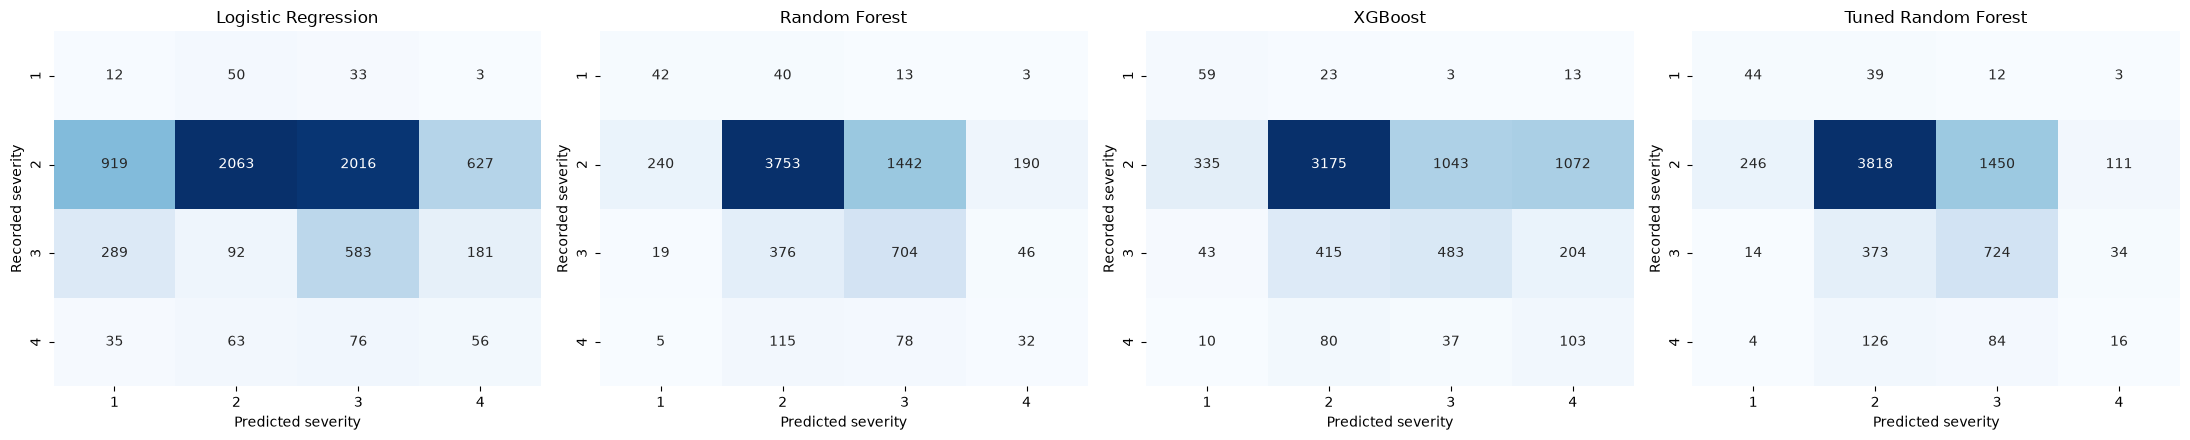

In [8]:
labels = [1, 2, 3, 4]
fig, axes = plt.subplots(1, len(predictions), figsize=(5.5 * len(predictions), 4.5))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, predictions.items()):
    print("\n", name)
    print(classification_report(y_test, pred, labels=labels, zero_division=0, digits=3))
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted severity")
    ax.set_ylabel("Recorded severity")
plt.tight_layout()
plt.show()


## 9. High-risk patterns for investigation

These charts show observed accident counts and the share recorded as severity 3 or 4. A higher share is an association in this dataset, not proof that the condition causes severity.

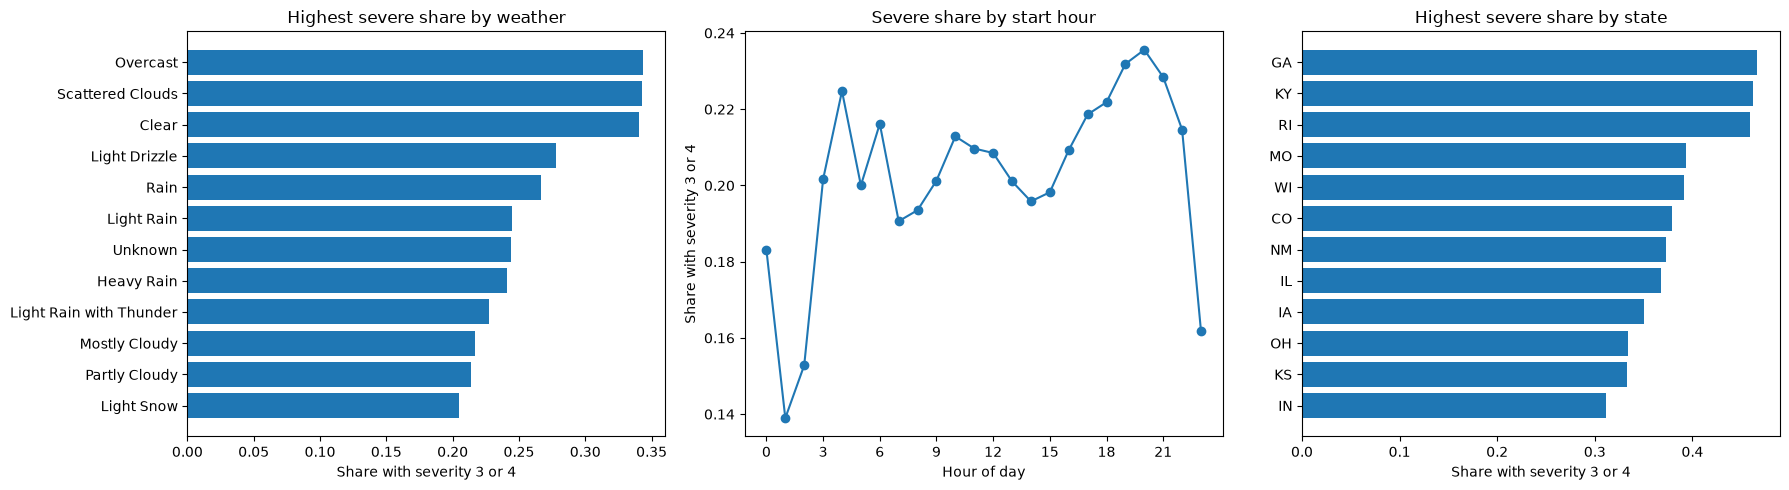

,Weather_Condition,Accident_Count,Severe_Share
48,Overcast,4131,0.343258
57,Scattered Clouds,2304,0.342448
4,Clear,8739,0.340771
27,Light Drizzle,263,0.277567
52,Rain,900,0.266667
32,Light Rain,3756,0.244941
73,Unknown,1839,0.244154
18,Heavy Rain,357,0.240896
36,Light Rain with Thunder,154,0.227273
45,Mostly Cloudy,10994,0.216846


,Hour,Accident_Count,Severe_Share
0,0,1087,0.183073
1,1,1029,0.138970
2,2,975,0.152821
3,3,868,0.201613
4,4,1762,0.224745
5,5,2485,0.200000
6,6,4427,0.216173
7,7,6584,0.190614
8,8,6537,0.193514
9,9,3950,0.201266


,State,Accident_Count,Severe_Share
9,GA,1844,0.466377
15,KY,355,0.461972
37,RI,205,0.458537
22,MO,833,0.393758
46,WI,355,0.391549
4,CO,948,0.378692
30,NM,110,0.372727
12,IL,1892,0.367336
10,IA,294,0.350340
33,OH,1328,0.334337


In [9]:
df["Severe_3_or_4"] = (df["Severity"] >= 3).astype(int)

def summarize_group(column, min_count=100):
    result = df.groupby(column, dropna=False).agg(
        Accident_Count=("Severity", "size"),
        Severe_Share=("Severe_3_or_4", "mean"),
    ).reset_index()
    return result[result["Accident_Count"] >= min_count].sort_values(
        "Severe_Share", ascending=False
    )

weather_summary = summarize_group("Weather_Condition")
hour_summary = summarize_group("Hour", min_count=1).sort_values("Hour")
state_summary = summarize_group("State")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
weather_plot = weather_summary.head(12).sort_values("Severe_Share")
axes[0].barh(weather_plot["Weather_Condition"], weather_plot["Severe_Share"])
axes[0].set_title("Highest severe share by weather")
axes[0].set_xlabel("Share with severity 3 or 4")

axes[1].plot(hour_summary["Hour"], hour_summary["Severe_Share"], marker="o")
axes[1].set_title("Severe share by start hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Share with severity 3 or 4")
axes[1].set_xticks(range(0, 24, 3))

state_plot = state_summary.head(12).sort_values("Severe_Share")
axes[2].barh(state_plot["State"], state_plot["Severe_Share"])
axes[2].set_title("Highest severe share by state")
axes[2].set_xlabel("Share with severity 3 or 4")
plt.tight_layout()
plt.show()

display(weather_summary.head(10))
display(hour_summary)
display(state_summary.head(10))


## 10. Review model errors

Inspect which severity pairs are most often confused by the model with the best location-split macro-F1.

In [10]:
best_name = comparison.iloc[0]["Algorithm"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print("Top macro-F1 model on location split:", best_name)

errors = pd.DataFrame({"Actual": y_test.to_numpy(), "Predicted": best_pred})
errors = errors[errors["Actual"] != errors["Predicted"]]
if errors.empty:
    print("No errors in this test sample.")
else:
    print("Most common misclassifications:")
    display(errors.value_counts().rename("Count").reset_index().head(10))


Top macro-F1 model on location split: Random Forest
Most common misclassifications:


,Actual,Predicted,Count
0,2,3,1442
1,3,2,376
2,2,1,240
3,2,4,190
4,4,2,115
5,4,3,78
6,3,4,46
7,1,2,40
8,3,1,19
9,1,3,13


## 11. Check generalization to a later time period

This additional check trains on earlier records and evaluates on the latest 20% of dates. It uses the selected model and the same feature preprocessing.

In [11]:
ordered_idx = df["Start_Time"].sort_values().index
cut_position = int(len(ordered_idx) * 0.80)
time_train_idx = ordered_idx[:cut_position]
time_test_idx = ordered_idx[cut_position:]

time_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", clone(best_model.named_steps["model"])),
])
time_fit_params = {}
if model_family == "XGBoost":
    time_fit_params["model__sample_weight"] = compute_sample_weight(
        "balanced", df.loc[time_train_idx, "Severity"]
    )
time_y_train = y.loc[time_train_idx] - 1 if model_family == "XGBoost" else y.loc[time_train_idx]
time_model.fit(X.loc[time_train_idx], time_y_train, **time_fit_params)
time_pred = time_model.predict(X.loc[time_test_idx])
if model_family == "XGBoost":
    time_pred = time_pred + 1
print("Time test period:", df.loc[time_test_idx, "Start_Time"].min(), "to", df.loc[time_test_idx, "Start_Time"].max())
print("Time-split macro-F1:", round(f1_score(y.loc[time_test_idx], time_pred, average="macro"), 3))
print(classification_report(y.loc[time_test_idx], time_pred, labels=[1, 2, 3, 4], zero_division=0, digits=3))


Time test period: 2022-02-10 16:44:49 to 2023-03-31 22:34:07
Time-split macro-F1: 0.311
              precision    recall  f1-score   support

           1      0.030     0.002     0.004       447
           2      0.913     0.890     0.901     14928
           3      0.176     0.239     0.203       784
           4      0.099     0.224     0.137       410

    accuracy                          0.819     16569
   macro avg      0.305     0.339     0.311     16569
weighted avg      0.834     0.819     0.825     16569



## 12. Retrain on the retained sample and save for FastAPI

After evaluation, retrain the selected model on every row in the sample of up to 100,000 rows and save the exact feature order expected by the API. The reported evaluation scores still come from the held-out location and time checks.

In [12]:
OUTPUT_DIR = Path("model_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUTPUT_DIR / "accident_severity_pipeline.joblib"

final_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", clone(best_model.named_steps["model"])),
])
final_fit_params = {}
final_y = y - 1 if model_family == "XGBoost" else y
if model_family == "XGBoost":
    final_fit_params["model__sample_weight"] = compute_sample_weight("balanced", y)
final_model.fit(X, final_y, **final_fit_params)

joblib.dump({
    "pipeline": final_model,
    "features": feature_columns,
    "classes": [1, 2, 3, 4],
    "selected_model": best_model_key,
    "minority_class": minority_class,
    "prediction_offset": 1 if model_family == "XGBoost" else 0,
}, MODEL_PATH, compress=3)

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Saved model:", MODEL_PATH.resolve())
print("Saved comparison:", (OUTPUT_DIR / "model_comparison.csv").resolve())


Saved model: C:\25BD1A05E4\Road_Accident_Severity_Render_Project\Road_Accident_Severity_Project\model_output\accident_severity_pipeline.joblib
Saved comparison: C:\25BD1A05E4\Road_Accident_Severity_Render_Project\Road_Accident_Severity_Project\model_output\model_comparison.csv


In [13]:
from pathlib import Path

model_path = Path("model_output/accident_severity_pipeline.joblib")
print("Notebook folder:", Path.cwd())
print("Expected model path:", model_path.resolve())
print("File exists:", model_path.exists())

Notebook folder: C:\25BD1A05E4\Road_Accident_Severity_Render_Project\Road_Accident_Severity_Project
Expected model path: C:\25BD1A05E4\Road_Accident_Severity_Render_Project\Road_Accident_Severity_Project\model_output\accident_severity_pipeline.joblib
File exists: True
